# Análisis Exploratorio de Datos
## Mantenimiento predictivo de camiones

Este notebook forma parte del proyecto final del curso de Data Science.

El análisis utiliza información histórica mensual de una flota de camiones con el objetivo de estudiar los patrones asociados a la aparición de fallas y mantenimientos correctivos.

A partir del análisis exploratorio se buscará comprender la estructura y calidad de los datos, identificar patrones de utilización y mantenimiento, analizar las variables relacionadas con las fallas y determinar qué información podría resultar útil para construir posteriormente un modelo predictivo.

## 1. Objetivo del análisis

El objetivo del proyecto es analizar si la información histórica y operativa de los camiones permite identificar patrones asociados a la aparición de fallas que requieran mantenimiento correctivo.

Los mantenimientos preventivos no forman parte del objetivo del análisis, ya que son intervenciones programadas cuya ocurrencia se conoce de antemano.

En esta primera etapa se realizará un Análisis Exploratorio de Datos (AED) para comprender el dataset, evaluar su calidad y estudiar las relaciones existentes entre el uso de los equipos, sus características y la ocurrencia de fallas.

## 1. Carga de datos

In [1]:
import pandas as pd

ruta = "../data/raw/dataset_registro_fallas_x_mes_CAMIONES.csv"

df = pd.read_csv(ruta, sep=";")

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df.head()

Filas: 7874
Columnas: 35


,EQUIPO,PERIODO,SUBUN,REQUIRIO_MANT,F_MOTOR,F_LUB_REFRIG,F_TRANSMISION,F_FRENOS,F_NEUMATICO,F_HIDRAULICO,...,SIN_EVENTO_PREVIO,HS_MES,KM_MES,RAL_MES,HSOPE_MES,TIPO_CHASIS,CAPACIDAD_TN,RUTINA_MANT,CONSUMO_HS,CONSUMO_KM
0,C3,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,105.0,74.0,93.0,NaN,DM800,58,PETROLERO,"4,05","5,13"
1,C5,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,21.0,29.0,11.0,NaN,CON GUINCHE,58,PETROLERO,"17,15","3,29"
2,C8,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,29.0,106.0,23.0,NaN,DM800,58,PETROLERO,"5,11","0,67"
3,C14,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,245.0,173.0,226.0,NaN,DM32,58,PETROLERO,"3,11","3,11"
4,C16,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,56.0,277.0,42.0,NaN,DM800,45,PETROLERO,"6,16","0,81"


In [2]:
print("TIPOS DE DATOS:")
print(df.dtypes)

print("\nVALORES FALTANTES:")
print(df.isnull().sum())

print("\nREGISTROS DUPLICADOS:")
print(df.duplicated().sum())

TIPOS DE DATOS:
EQUIPO                   str
PERIODO                  str
SUBUN                    str
REQUIRIO_MANT            str
F_MOTOR              float64
F_LUB_REFRIG         float64
F_TRANSMISION        float64
F_FRENOS             float64
F_NEUMATICO          float64
F_HIDRAULICO         float64
F_SUSPENSION         float64
F_ELECTRICO          float64
F_CABINA             float64
F_CARGA              float64
F_OTROS              float64
CANT_REP             float64
TIPOEQ                   str
SUBTIPO                  str
MARCA                    str
MODELO                   str
ANIO                 float64
HS_DESDE_ULT         float64
KM_DESDE_ULT         float64
RAL_DESDE_ULT        float64
DIAS_DESDE_ULT       float64
SIN_EVENTO_PREVIO    float64
HS_MES               float64
KM_MES               float64
RAL_MES              float64
HSOPE_MES            float64
TIPO_CHASIS              str
CAPACIDAD_TN             str
RUTINA_MANT              str
CONSUMO_HS               st

## 2. Descripción del dataset

El dataset contiene información histórica mensual correspondiente a los camiones de la flota.

Cada fila representa un equipo durante un período mensual determinado, por lo que la combinación de `EQUIPO` y `PERIODO` identifica una observación.

Las variables disponibles pueden agruparse en los siguientes tipos de información:

### Identificación y características del equipo
Incluyen información como:

- equipo;
- subunidad;
- tipo y subtipo de equipo;
- marca y modelo;
- año;
- tipo de chasis;
- capacidad;
- rutina de mantenimiento.

### Fallas y mantenimiento correctivo
Permiten identificar si el equipo requirió mantenimiento correctivo durante el período y qué sistemas fueron afectados.

Se incluyen fallas relacionadas con:

- motor;
- lubricación y refrigeración;
- transmisión;
- frenos;
- sistema neumático;
- sistema hidráulico;
- suspensión;
- sistema eléctrico;
- cabina;
- sistema de carga.

La variable `REQUIRIO_MANT` indica si durante el período se registró al menos un evento de mantenimiento correctivo.

### Utilización mensual
Estas variables describen el nivel de utilización del equipo durante cada mes:

- horas de uso (`HS_MES`);
- kilómetros recorridos (`KM_MES`);
- ralentí (`RAL_MES`);
- horas operativas (`HSOPE_MES`);
- indicadores de consumo.

### Historial desde el último mantenimiento correctivo
El dataset también contiene variables que permiten conocer cuánto tiempo o utilización transcurrió desde el último evento correctivo registrado:

- `HS_DESDE_ULT`;
- `KM_DESDE_ULT`;
- `RAL_DESDE_ULT`;
- `DIAS_DESDE_ULT`;
- `SIN_EVENTO_PREVIO`.

Estas variables resultan especialmente interesantes para analizar si la acumulación de uso desde una reparación anterior está relacionada con la aparición de una nueva falla.

### 3.1 Problemas detectados en la calidad de los datos

La exploración inicial permitió detectar algunos aspectos que deben revisarse antes de continuar con el análisis:

1. **El dataset no posee un identificador único para cada observación.**  
   La columna `EQUIPO` se repite porque un mismo camión aparece en diferentes períodos. Dado que cada fila representa un equipo en un mes determinado, se analizará la combinación `EQUIPO + PERIODO` como posible clave compuesta.

2. **Las variables de fallas contienen una gran cantidad de valores faltantes.**  
   Las columnas `F_MOTOR`, `F_FRENOS`, `F_ELECTRICO`, entre otras, presentan numerosos valores `NaN`. En estos casos, el valor faltante representa que no ocurrió una falla de ese sistema durante el período.

3. **Algunas variables numéricas fueron interpretadas como texto.**  
   Variables como `CAPACIDAD_TN`, `CONSUMO_HS` y `CONSUMO_KM` deberán revisarse y convertirse posteriormente al tipo de dato correspondiente.

4. **Existen valores faltantes en otras variables.**  
   Columnas como `SUBUN`, `MODELO`, `ANIO`, `RUTINA_MANT` y algunas variables de utilización presentan datos faltantes que deberán analizarse individualmente antes de decidir su tratamiento.

### 3.2 Problema 1: El dataset no posee un identificador único para cada observación


In [3]:
duplicados_equipo_periodo = df.duplicated(
    subset=["EQUIPO", "PERIODO"]
).sum()

print("Duplicados EQUIPO + PERIODO:", duplicados_equipo_periodo)

Duplicados EQUIPO + PERIODO: 0


    **Conclusión** no se encontraron registros duplicados para una misma combinación de equipo y período.

Dado que cada fila representa el comportamiento de un equipo durante un mes determinado, se define la combinación `EQUIPO + PERIODO` como clave compuesta del dataset.

A partir de esta combinación se crea la variable `ID`, que permite identificar de manera única cada observación, manteniendo al mismo tiempo `EQUIPO` y `PERIODO` como variables independientes para los análisis posteriores.

In [4]:
df["ID"] = df["EQUIPO"].astype(str) + "_" + df["PERIODO"].astype(str)
df.insert(0, "ID", df.pop("ID"))

df.head()

,ID,EQUIPO,PERIODO,SUBUN,REQUIRIO_MANT,F_MOTOR,F_LUB_REFRIG,F_TRANSMISION,F_FRENOS,F_NEUMATICO,...,SIN_EVENTO_PREVIO,HS_MES,KM_MES,RAL_MES,HSOPE_MES,TIPO_CHASIS,CAPACIDAD_TN,RUTINA_MANT,CONSUMO_HS,CONSUMO_KM
0,C3_2024-01,C3,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,...,1.0,105.0,74.0,93.0,NaN,DM800,58,PETROLERO,"4,05","5,13"
1,C5_2024-01,C5,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,...,1.0,21.0,29.0,11.0,NaN,CON GUINCHE,58,PETROLERO,"17,15","3,29"
2,C8_2024-01,C8,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,...,1.0,29.0,106.0,23.0,NaN,DM800,58,PETROLERO,"5,11","0,67"
3,C14_2024-01,C14,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,...,1.0,245.0,173.0,226.0,NaN,DM32,58,PETROLERO,"3,11","3,11"
4,C16_2024-01,C16,2024-01,DTM-02,NO,NaN,NaN,NaN,NaN,NaN,...,1.0,56.0,277.0,42.0,NaN,DM800,45,PETROLERO,"6,16","0,81"


## 3.3 Problema 2: valores faltantes en las variables de fallas

Durante la exploración se observó una gran cantidad de valores faltantes (`NaN`) en las variables que representan los distintos sistemas de falla, como `F_MOTOR`, `F_FRENOS`, `F_ELECTRICO`, entre otras.

En estas variables, un valor faltante no representa información desconocida. Según la construcción del dataset, indica que durante ese período **no se registró una falla en ese sistema**.

Por lo tanto, estas variables deberían comportarse como variables binarias:

- `1`: se registró una falla en el sistema.
- `0`: no se registró una falla en el sistema.

Antes de realizar la transformación, se analizarán los valores presentes en estas columnas para comprobar su estructura actual.

In [5]:
columnas_fallas = [
    "F_MOTOR",
    "F_LUB_REFRIG",
    "F_TRANSMISION",
    "F_FRENOS",
    "F_NEUMATICO",
    "F_HIDRAULICO",
    "F_SUSPENSION",
    "F_ELECTRICO",
    "F_CABINA",
    "F_CARGA",
    "F_OTROS"
]

for columna in columnas_fallas:
    print(f"\n{columna}:")
    print(df[columna].value_counts(dropna=False))


F_MOTOR:
F_MOTOR
NaN    7465
1.0     409
Name: count, dtype: int64

F_LUB_REFRIG:
F_LUB_REFRIG
NaN    7635
1.0     239
Name: count, dtype: int64

F_TRANSMISION:
F_TRANSMISION
NaN    7643
1.0     231
Name: count, dtype: int64

F_FRENOS:
F_FRENOS
NaN    7592
1.0     282
Name: count, dtype: int64

F_NEUMATICO:
F_NEUMATICO
NaN    7731
1.0     143
Name: count, dtype: int64

F_HIDRAULICO:
F_HIDRAULICO
NaN    7624
1.0     250
Name: count, dtype: int64

F_SUSPENSION:
F_SUSPENSION
NaN    7549
1.0     325
Name: count, dtype: int64

F_ELECTRICO:
F_ELECTRICO
NaN    6232
1.0    1642
Name: count, dtype: int64

F_CABINA:
F_CABINA
NaN    7205
1.0     669
Name: count, dtype: int64

F_CARGA:
F_CARGA
NaN    7549
1.0     325
Name: count, dtype: int64

F_OTROS:
F_OTROS
NaN    7874
Name: count, dtype: int64


**Conclusión:** el análisis de las variables de fallas muestra que únicamente contienen el valor `1` cuando se registró una falla y `NaN` cuando no se registró ninguna.

Por lo tanto, estos valores faltantes no representan datos desconocidos, sino la ausencia de una falla.

Se decide transformar estas variables en variables binarias:

- `1`: ocurrió una falla en el sistema.
- `0`: no ocurrió una falla en el sistema.

También se observa que `F_OTROS` no contiene ninguna falla registrada en todo el dataset, por lo que actualmente no aporta información al análisis.

In [6]:
df[columnas_fallas] = df[columnas_fallas].fillna(0).astype(int)

df[columnas_fallas].head()

,F_MOTOR,F_LUB_REFRIG,F_TRANSMISION,F_FRENOS,F_NEUMATICO,F_HIDRAULICO,F_SUSPENSION,F_ELECTRICO,F_CABINA,F_CARGA,F_OTROS
0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0


In [7]:
print("Valores faltantes luego de la transformación:")
print(df[columnas_fallas].isnull().sum())

print("\nValores posibles:")
for columna in columnas_fallas:
    print(columna, sorted(df[columna].unique()))

Valores faltantes luego de la transformación:
F_MOTOR          0
F_LUB_REFRIG     0
F_TRANSMISION    0
F_FRENOS         0
F_NEUMATICO      0
F_HIDRAULICO     0
F_SUSPENSION     0
F_ELECTRICO      0
F_CABINA         0
F_CARGA          0
F_OTROS          0
dtype: int64

Valores posibles:
F_MOTOR [np.int64(0), np.int64(1)]
F_LUB_REFRIG [np.int64(0), np.int64(1)]
F_TRANSMISION [np.int64(0), np.int64(1)]
F_FRENOS [np.int64(0), np.int64(1)]
F_NEUMATICO [np.int64(0), np.int64(1)]
F_HIDRAULICO [np.int64(0), np.int64(1)]
F_SUSPENSION [np.int64(0), np.int64(1)]
F_ELECTRICO [np.int64(0), np.int64(1)]
F_CABINA [np.int64(0), np.int64(1)]
F_CARGA [np.int64(0), np.int64(1)]
F_OTROS [np.int64(0)]


In [8]:
df.head()

,ID,EQUIPO,PERIODO,SUBUN,REQUIRIO_MANT,F_MOTOR,F_LUB_REFRIG,F_TRANSMISION,F_FRENOS,F_NEUMATICO,...,SIN_EVENTO_PREVIO,HS_MES,KM_MES,RAL_MES,HSOPE_MES,TIPO_CHASIS,CAPACIDAD_TN,RUTINA_MANT,CONSUMO_HS,CONSUMO_KM
0,C3_2024-01,C3,2024-01,DTM-02,NO,0,0,0,0,0,...,1.0,105.0,74.0,93.0,NaN,DM800,58,PETROLERO,"4,05","5,13"
1,C5_2024-01,C5,2024-01,DTM-02,NO,0,0,0,0,0,...,1.0,21.0,29.0,11.0,NaN,CON GUINCHE,58,PETROLERO,"17,15","3,29"
2,C8_2024-01,C8,2024-01,DTM-02,NO,0,0,0,0,0,...,1.0,29.0,106.0,23.0,NaN,DM800,58,PETROLERO,"5,11","0,67"
3,C14_2024-01,C14,2024-01,DTM-02,NO,0,0,0,0,0,...,1.0,245.0,173.0,226.0,NaN,DM32,58,PETROLERO,"3,11","3,11"
4,C16_2024-01,C16,2024-01,DTM-02,NO,0,0,0,0,0,...,1.0,56.0,277.0,42.0,NaN,DM800,45,PETROLERO,"6,16","0,81"


### 3.4 Problema 3: variables numéricas interpretadas como texto

Durante la revisión de los tipos de datos se detectó que algunas variables que conceptualmente representan cantidades numéricas fueron interpretadas por Pandas como texto (`str`).

Las variables identificadas son:

- `CAPACIDAD_TN`: capacidad del equipo expresada en toneladas.
- `CONSUMO_HS`: indicador de consumo asociado a las horas de utilización.
- `CONSUMO_KM`: indicador de consumo asociado a los kilómetros recorridos.

Antes de realizar cualquier conversión, se analizarán los valores presentes en estas columnas para identificar por qué fueron interpretadas como texto y comprobar si pueden convertirse correctamente a variables numéricas.

In [9]:
columnas_revisar = [
    "CAPACIDAD_TN",
    "CONSUMO_HS",
    "CONSUMO_KM"
]

for columna in columnas_revisar:
    print(f"\n{columna}")
    print("Tipo:", df[columna].dtype)
    print("Valores de ejemplo:")
    print(df[columna].dropna().unique()[:20])



CAPACIDAD_TN
Tipo: str
Valores de ejemplo:
<ArrowStringArray>
['58', '45', '0', '16,5', '28', '24', '30', '3']
Length: 8, dtype: str

CONSUMO_HS
Tipo: str
Valores de ejemplo:
<ArrowStringArray>
[ '4,05', '17,15',  '5,11',  '3,11',  '6,16',  '4,88',  '5,17',  '4,83',
  '4,45', '12,87',  '4,21',  '4,12', '10,89',  '4,82',  '3,76',  '4,15',
  '3,65',  '5,76',  '0,41',  '4,77']
Length: 20, dtype: str

CONSUMO_KM
Tipo: str
Valores de ejemplo:
<ArrowStringArray>
['5,13', '3,29', '0,67', '3,11', '0,81', '0,57',  '5,1', '0,96',  '4,8',
 '6,42', '0,66', '4,31', '3,84', '0,76', '1,09', '6,36', '8,29', '0,11',
 '4,63', '0,95']
Length: 20, dtype: str


**Conclusión:** las variables `CAPACIDAD_TN`, `CONSUMO_HS` y `CONSUMO_KM` contienen valores que representan cantidades numéricas, pero fueron interpretadas como texto debido al uso de la coma como separador decimal.

Por ejemplo:

- `16,5` representa `16.5` toneladas.
- `4,05` representa el valor numérico `4.05`.
- `5,13` representa el valor numérico `5.13`.

Para poder realizar cálculos estadísticos y analizar posteriormente estas variables, se reemplazará la coma decimal por un punto y se convertirán las columnas a tipo numérico.

In [10]:
columnas_numericas = [
    "CAPACIDAD_TN",
    "CONSUMO_HS",
    "CONSUMO_KM"
]

for columna in columnas_numericas:
    df[columna] = pd.to_numeric(
        df[columna].str.replace(",", ".", regex=False),
        errors="coerce"
    )

In [11]:
print("TIPOS DE DATOS:")
print(df[columnas_numericas].dtypes)

print("\nVALORES FALTANTES:")
print(df[columnas_numericas].isnull().sum())

print("\nEJEMPLO DE LOS DATOS:")
df[columnas_numericas].head()

TIPOS DE DATOS:
CAPACIDAD_TN    float64
CONSUMO_HS      float64
CONSUMO_KM      float64
dtype: object

VALORES FALTANTES:
CAPACIDAD_TN    0
CONSUMO_HS      0
CONSUMO_KM      0
dtype: int64

EJEMPLO DE LOS DATOS:


,CAPACIDAD_TN,CONSUMO_HS,CONSUMO_KM
0,58.0,4.05,5.13
1,58.0,17.15,3.29
2,58.0,5.11,0.67
3,58.0,3.11,3.11
4,45.0,6.16,0.81


### 3.5 Problema 4: valores faltantes en otras variables

Luego de tratar las variables de fallas, todavía existen valores faltantes en distintas columnas del dataset.

A diferencia de las variables `F_`, en estos casos no podemos asumir que un valor faltante equivale a cero. La ausencia de información puede tener diferentes causas según la variable.

Por este motivo, antes de completar, eliminar o transformar estos valores, se analizará la cantidad y el porcentaje de datos faltantes de cada columna.

In [12]:
faltantes = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": (df.isnull().mean() * 100).round(2)
})

faltantes = faltantes[faltantes["Cantidad"] > 0]
faltantes = faltantes.sort_values("Porcentaje", ascending=False)

faltantes

,Cantidad,Porcentaje
TIPO_CHASIS,6386,81.10
CANT_REP,5157,65.49
SIN_EVENTO_PREVIO,5151,65.42
HSOPE_MES,4062,51.59
KM_DESDE_ULT,3517,44.67
RAL_DESDE_ULT,3461,43.95
HS_DESDE_ULT,3409,43.29
DIAS_DESDE_ULT,2723,34.58
KM_MES,2016,25.60
RAL_MES,1917,24.35



Luego de analizar el origen de los valores faltantes, se determinó que varias variables utilizan `NaN` para representar ausencia de información o ausencia de actividad registrada.

Para estas variables se adopta el valor `0`:

- `CANT_REP`: no se registraron reparaciones.
- `SIN_EVENTO_PREVIO`: se reemplazan los valores faltantes por `0`.
- `HSOPE_MES`, `HS_MES`, `KM_MES` y `RAL_MES`: no se registró utilización durante el período.
- `HS_DESDE_ULT`, `KM_DESDE_ULT`, `RAL_DESDE_ULT` y `DIAS_DESDE_ULT`: cuando no existe un valor acumulado disponible, se representa con `0`.

En cambio, los valores faltantes de `TIPO_CHASIS`, `RUTINA_MANT`, `SUBUN`, `MODELO` y `ANIO` corresponden a información que no fue cargada y no serán reemplazados por cero, ya que esto generaría valores artificiales.

In [13]:
columnas_reemplazar_cero = [
    "CANT_REP",
    "SIN_EVENTO_PREVIO",
    "HSOPE_MES",
    "HS_MES",
    "KM_MES",
    "RAL_MES",
    "HS_DESDE_ULT",
    "KM_DESDE_ULT",
    "RAL_DESDE_ULT",
    "DIAS_DESDE_ULT"
]

df[columnas_reemplazar_cero] = df[columnas_reemplazar_cero].fillna(0)

# Variables que conceptualmente son enteras
df["CANT_REP"] = df["CANT_REP"].astype(int)
df["SIN_EVENTO_PREVIO"] = df["SIN_EVENTO_PREVIO"].astype(int)

print("Valores faltantes luego de la transformación:")
print(df[columnas_reemplazar_cero].isnull().sum())

Valores faltantes luego de la transformación:
CANT_REP             0
SIN_EVENTO_PREVIO    0
HSOPE_MES            0
HS_MES               0
KM_MES               0
RAL_MES              0
HS_DESDE_ULT         0
KM_DESDE_ULT         0
RAL_DESDE_ULT        0
DIAS_DESDE_ULT       0
dtype: int64


#### Valores faltantes correspondientes a información desconocida

Luego de aplicar las transformaciones anteriores, los valores faltantes que permanecen en `TIPO_CHASIS`, `RUTINA_MANT`, `SUBUN`, `MODELO` y `ANIO` tienen un significado diferente.

En estos casos, el valor faltante representa información que no fue cargada o que no se encuentra disponible en las fuentes originales. Por lo tanto, se consideran **datos realmente desconocidos**.

No se reemplazarán por `0`, ya que esto introduciría información incorrecta. Su tratamiento definitivo se evaluará posteriormente según la utilidad de cada variable y las necesidades del análisis o del modelo.

En particular, `TIPO_CHASIS` presenta una proporción elevada de valores faltantes, por lo que deberá evaluarse si resulta conveniente utilizar esta variable en etapas posteriores.

### 3.6 Exportación del dataset procesado

Una vez finalizada la limpieza y transformación inicial, se guarda una nueva versión del dataset en la carpeta `data/processed`.

El archivo original ubicado en `data/raw` se conserva sin modificaciones. Esto permite mantener una copia de los datos originales y, al mismo tiempo, utilizar una versión limpia y preparada para los análisis posteriores.

La versión procesada incluye:

- una columna `ID` como identificador único;
- variables de fallas transformadas a valores binarios;
- variables numéricas convertidas al tipo correspondiente;
- valores faltantes reemplazados por `0` cuando representan ausencia de fallas, reparaciones o utilización;
- valores realmente desconocidos conservados como `NaN`.

A partir de este punto, los análisis posteriores utilizarán el dataset procesado.


In [14]:
from pathlib import Path

ruta_processed = Path(
    "../data/processed/dataset_registro_fallas_x_mes_CAMIONES_PROCESADO.csv"
)

# Crea la carpeta processed si todavía no existe
ruta_processed.parent.mkdir(parents=True, exist_ok=True)

# Guarda el dataset limpio
df.to_csv(
    ruta_processed,
    sep=";",
    decimal=",",
    index=False
)

print("Dataset procesado guardado correctamente en:")
print(ruta_processed)

Dataset procesado guardado correctamente en:
..\data\processed\dataset_registro_fallas_x_mes_CAMIONES_PROCESADO.csv


## 4. Análisis Exploratorio de Datos

Una vez finalizada la limpieza y preparación inicial de los datos, comenzamos el análisis exploratorio.

El objetivo de esta etapa es comprender las características de la flota y buscar patrones relacionados con la ocurrencia de fallas correctivas.

### 4.1 Cobertura del dataset

En primer lugar, analizamos la cobertura de la información disponible.

Buscamos conocer:

- cuántos equipos diferentes contiene el dataset;
- qué período temporal abarcan los registros;
- cuántos meses de información tenemos;
- cuántas observaciones existen por equipo.

Esto permitirá conocer cuánto historial tenemos disponible antes de comenzar a analizar las fallas.

In [15]:
print("Cantidad de registros:", len(df))
print("Cantidad de equipos:", df["EQUIPO"].nunique())

print("\nPrimer período:", df["PERIODO"].min())
print("Último período:", df["PERIODO"].max())

print("\nCantidad de períodos:", df["PERIODO"].nunique())

observaciones_por_equipo = df.groupby("EQUIPO")["PERIODO"].nunique()

print("\nObservaciones por equipo:")
print(observaciones_por_equipo.describe())

Cantidad de registros: 7874
Cantidad de equipos: 254

Primer período: 2024-01
Último período: 2026-07

Cantidad de períodos: 31

Observaciones por equipo:
count    254.0
mean      31.0
std        0.0
min       31.0
25%       31.0
50%       31.0
75%       31.0
max       31.0
Name: PERIODO, dtype: float64


**Conclusión:** el dataset contiene 7.874 observaciones correspondientes a 254 equipos diferentes, registrados mensualmente entre enero de 2024 y julio de 2026.

Se dispone de un total de 31 períodos mensuales y todos los equipos poseen exactamente 31 observaciones.

Esto indica que el dataset presenta una cobertura temporal completa y uniforme: cada equipo cuenta con un registro para cada mes del período analizado.

Esta característica resulta favorable para los análisis posteriores, ya que permite comparar los equipos sobre una misma ventana temporal y estudiar su evolución sin diferencias en la cantidad de períodos observados.

### 4.2 Frecuencia de mantenimiento correctivo

Una vez conocida la cobertura del dataset, analizamos con qué frecuencia los equipos presentan fallas que requieren mantenimiento correctivo.

La variable `REQUIRIO_MANT` indica si durante un período determinado el equipo presentó al menos una falla correctiva.

El objetivo es conocer:

- cuántos registros corresponden a períodos con mantenimiento correctivo;
- cuántos corresponden a períodos sin mantenimiento correctivo;
- qué porcentaje representa cada grupo;
- si existe un desbalance importante entre ambas clases.

In [16]:
cantidad = df["REQUIRIO_MANT"].value_counts()
porcentaje = df["REQUIRIO_MANT"].value_counts(normalize=True) * 100

resumen_mantenimiento = pd.DataFrame({
    "Cantidad": cantidad,
    "Porcentaje": porcentaje.round(2)
})

resumen_mantenimiento

,Cantidad,Porcentaje
REQUIRIO_MANT,,
NO,5157,65.49
SI,2717,34.51


**Conclusión:** de las 7.874 observaciones del dataset, 2.717 (34,51 %) corresponden a períodos en los que el equipo requirió mantenimiento correctivo, mientras que 5.157 (65,49 %) corresponden a períodos sin mantenimiento correctivo.

Existe un desbalance moderado entre ambas clases, ya que los períodos sin fallas son más frecuentes que los períodos con fallas.

Sin embargo, la clase asociada a mantenimiento correctivo representa aproximadamente un tercio de las observaciones, por lo que existe una cantidad considerable de ejemplos de ambos casos para continuar con el análisis.

Este desbalance deberá tenerse en cuenta posteriormente al evaluar los modelos de clasificación, evitando utilizar únicamente la exactitud como medida de desempeño.

### 4.3 Sistemas con mayor frecuencia de fallas

Luego de conocer la frecuencia general de mantenimiento correctivo, analizamos qué sistemas de los equipos presentan fallas con mayor frecuencia.

Las variables `F_` son binarias, donde:

- `1` indica que se registró una falla del sistema durante el período.
- `0` indica que no se registró una falla.

Por lo tanto, al sumar cada variable podemos obtener la cantidad de períodos en los que se registraron fallas para cada sistema.

In [17]:
frecuencia_fallas = (
    df[columnas_fallas]
    .sum()
    .sort_values(ascending=False)
)

frecuencia_fallas

F_ELECTRICO      1642
F_CABINA          669
F_MOTOR           409
F_SUSPENSION      325
F_CARGA           325
F_FRENOS          282
F_HIDRAULICO      250
F_LUB_REFRIG      239
F_TRANSMISION     231
F_NEUMATICO       143
F_OTROS             0
dtype: int64

**Conclusión:** las fallas no se distribuyen de manera uniforme entre los distintos sistemas del equipo.

El sistema eléctrico presenta la mayor cantidad de registros de falla, con 1.642 observaciones, seguido por cabina con 669 y motor con 409.

Luego aparecen suspensión y carga con 325 registros cada uno, mientras que neumáticos presenta la menor frecuencia entre los sistemas con fallas registradas, con 143 casos.

La variable `F_OTROS` no registra ninguna falla en todo el período analizado, por lo que no aporta información al análisis.

Estos resultados muestran que las fallas eléctricas tienen una presencia considerablemente mayor que el resto de los sistemas y constituyen uno de los principales tipos de mantenimiento correctivo de la flota.

#### Visualización de fallas por sistema

Para facilitar la comparación entre los diferentes sistemas se representa gráficamente la cantidad de registros de falla de cada categoría.

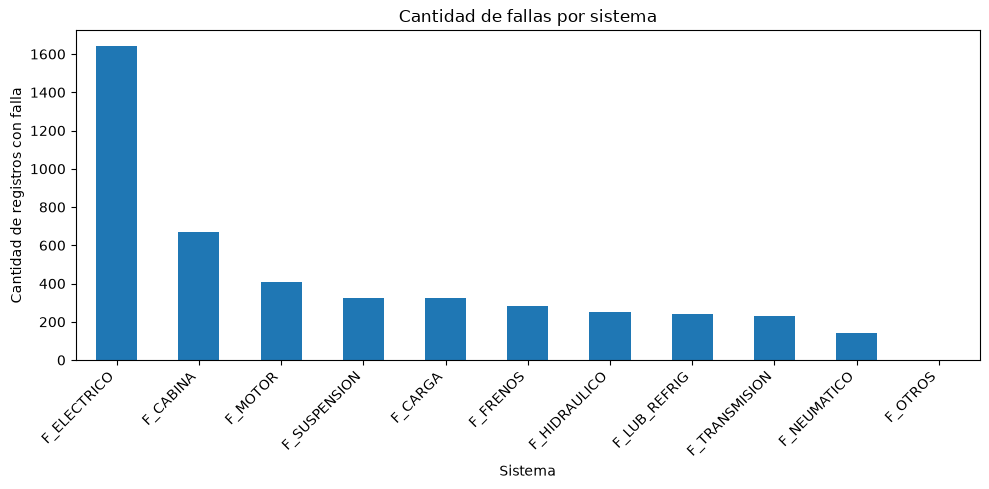

In [18]:
import matplotlib.pyplot as plt

frecuencia_fallas.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Cantidad de fallas por sistema")
plt.xlabel("Sistema")
plt.ylabel("Cantidad de registros con falla")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

La visualización permite observar con mayor claridad el predominio de las fallas eléctricas respecto del resto de los sistemas.

### 4.4 Comparación entre períodos con y sin mantenimiento correctivo

Luego de analizar la frecuencia y los tipos de fallas, buscamos determinar si existen diferencias en las características operativas de los equipos entre los períodos que requirieron mantenimiento correctivo y aquellos que no.

Para esta primera comparación se analizarán algunas variables relacionadas con el uso del equipo y con el tiempo transcurrido desde el último mantenimiento correctivo:

- `HS_MES`: horas registradas durante el mes.
- `KM_MES`: kilómetros registrados durante el mes.
- `RAL_MES`: ralentí registrado durante el mes.
- `HS_DESDE_ULT`: horas acumuladas desde el último correctivo.
- `KM_DESDE_ULT`: kilómetros acumulados desde el último correctivo.
- `RAL_DESDE_ULT`: ralentí acumulado desde el último correctivo.
- `DIAS_DESDE_ULT`: días desde el último mantenimiento correctivo.

El objetivo es observar si los períodos con fallas presentan valores diferentes de los períodos sin fallas.

In [19]:
variables_analisis = [
    "HS_MES",
    "KM_MES",
    "RAL_MES",
    "HS_DESDE_ULT",
    "KM_DESDE_ULT",
    "RAL_DESDE_ULT",
    "DIAS_DESDE_ULT"
]

comparacion = (
    df.groupby("REQUIRIO_MANT")[variables_analisis]
    .mean()
    .round(2)
)

comparacion

,HS_MES,KM_MES,RAL_MES,HS_DESDE_ULT,KM_DESDE_ULT,RAL_DESDE_ULT,DIAS_DESDE_ULT
REQUIRIO_MANT,,,,,,,
NO,131.14,1921.64,71.93,161.56,2607.46,86.04,40.80
SI,220.71,2954.59,121.75,219.06,3034.21,121.57,34.62


**Conclusión:** se observan diferencias entre los períodos con y sin mantenimiento correctivo.

Los períodos en los que se registraron fallas presentan, en promedio, mayores valores de horas de uso, kilómetros recorridos y ralentí durante el mes.

También se observan valores promedio superiores de horas, kilómetros y ralentí acumulados desde el último mantenimiento correctivo.

En cambio, `DIAS_DESDE_ULT` presenta un promedio ligeramente menor en los períodos con mantenimiento correctivo.

Estos resultados sugieren que las variables relacionadas con la intensidad de utilización del equipo podrían estar asociadas con la ocurrencia de fallas. Sin embargo, las diferencias observadas son descriptivas y deberán analizarse con mayor profundidad antes de determinar su utilidad predictiva.

#### Comparación visual de la utilización mensual

Las diferencias observadas en los promedios sugieren que los períodos con mantenimiento correctivo presentan una mayor utilización mensual.

Para analizar visualmente estas diferencias se comparan las distribuciones de horas, kilómetros y ralentí mensual entre períodos con y sin mantenimiento correctivo.

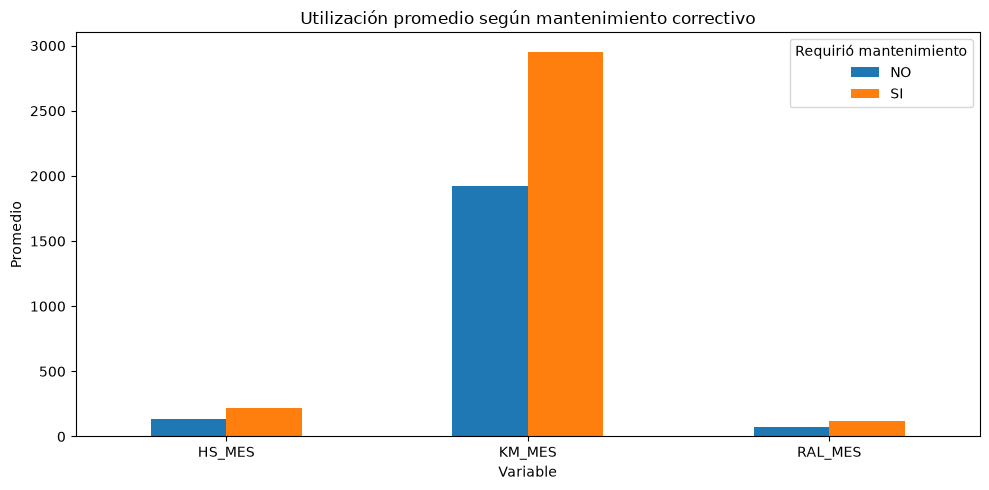

In [20]:
import matplotlib.pyplot as plt

variables = ["HS_MES", "KM_MES", "RAL_MES"]

df.groupby("REQUIRIO_MANT")[variables].mean().T.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Utilización promedio según mantenimiento correctivo")
plt.xlabel("Variable")
plt.ylabel("Promedio")
plt.xticks(rotation=0)
plt.legend(title="Requirió mantenimiento")
plt.tight_layout()
plt.show()

### 4.5 Fallas según características del equipo

Además de las variables relacionadas con la utilización, se analiza si la frecuencia de mantenimiento correctivo presenta diferencias según algunas características propias de los equipos.

En particular, se estudiarán:

- la marca del equipo;
- el subtipo;
- el año de fabricación.

El objetivo es identificar si determinados grupos de equipos presentan una mayor proporción de períodos con mantenimiento correctivo.

Este análisis será descriptivo y no implica que una característica sea necesariamente la causa de una mayor frecuencia de fallas.

In [24]:
fallas_por_marca = (
    df.assign(FALLA=(df["REQUIRIO_MANT"] == "SI").astype(int))
      .groupby("MARCA")
      .agg(
          REGISTROS=("FALLA", "size"),
          FALLAS=("FALLA", "sum"),
          TASA_FALLA=("FALLA", "mean")
      )
)

fallas_por_marca["TASA_FALLA"] = (
    fallas_por_marca["TASA_FALLA"] * 100
).round(2)

fallas_por_marca = fallas_por_marca.sort_values(
    "TASA_FALLA",
    ascending=False
)

fallas_por_marca

,REGISTROS,FALLAS,TASA_FALLA
MARCA,,,
SCONA,62,30,48.39
DELOUPE,62,29,46.77
VOLVO,1519,597,39.30
IVECO,372,146,39.25
SCANIA,4898,1686,34.42
ISUZU,62,20,32.26
MACK,310,96,30.97
KENWORTH,248,75,30.24
MERCEDES BENZ,31,7,22.58


#### Estandarización de la variable MARCA

Durante el análisis de las tasas de falla por marca se detectaron categorías que representan aparentemente la misma marca pero fueron registradas con diferente uso de mayúsculas y minúsculas.

Por ejemplo, `SCANIA` y `Scania` fueron interpretadas por Pandas como categorías diferentes.

Para evitar dividir artificialmente una misma categoría, se estandarizan los valores de `MARCA` utilizando mayúsculas.

In [26]:
fallas_por_marca = (
    df.assign(
        MARCA=df["MARCA"].str.upper().replace("SCONA", "SCANIA"),
        FALLA=(df["REQUIRIO_MANT"] == "SI").astype(int)
    )
    .groupby("MARCA")
    .agg(
        REGISTROS=("FALLA", "size"),
        FALLAS=("FALLA", "sum"),
        TASA_FALLA=("FALLA", "mean")
    )
)

fallas_por_marca["TASA_FALLA"] = (
    fallas_por_marca["TASA_FALLA"] * 100
).round(2)

fallas_por_marca.sort_values("TASA_FALLA", ascending=False)

,REGISTROS,FALLAS,TASA_FALLA
MARCA,,,
DELOUPE,62,29,46.77
VOLVO,1519,597,39.30
IVECO,372,146,39.25
SCANIA,4991,1716,34.38
ISUZU,62,20,32.26
MACK,310,96,30.97
KENWORTH,248,75,30.24
MERCEDES BENZ,31,7,22.58
FOTON,31,6,19.35


**Conclusión:** se observan diferencias en la frecuencia de mantenimiento correctivo entre las distintas marcas de la flota.

Sin embargo, la cantidad de observaciones disponibles para cada marca es muy diferente. Algunas marcas presentan tasas de falla elevadas pero cuentan con pocos registros, mientras que marcas como SCANIA y VOLVO poseen una cantidad considerablemente mayor de observaciones.

Por este motivo, las tasas de falla no deben interpretarse de manera aislada ni utilizarse para concluir que una marca es necesariamente más propensa a fallar.

El análisis muestra una asociación descriptiva entre la marca y la frecuencia de mantenimiento correctivo, pero existen otros factores que podrían explicar estas diferencias, como la antigüedad, el tipo de equipo o su nivel de utilización.

### 4.6 Antigüedad del equipo y ocurrencia de fallas

Finalmente, se analiza si la antigüedad de los equipos presenta alguna relación con la ocurrencia de mantenimiento correctivo.

La variable `ANIO` indica el año del equipo, pero resulta más interpretable expresar esta información como antigüedad.

Por este motivo, se crea una nueva variable denominada `ANTIGUEDAD`, calculada como la diferencia entre el año del período analizado y el año del equipo.

In [27]:
# Extraemos el año del período
anio_periodo = df["PERIODO"].str[:4].astype(int)

# Calculamos la antigüedad que tenía el equipo en cada período
df["ANTIGUEDAD"] = anio_periodo - df["ANIO"]

df[["EQUIPO", "PERIODO", "ANIO", "ANTIGUEDAD"]].head(10)

,EQUIPO,PERIODO,ANIO,ANTIGUEDAD
0,C3,2024-01,2009.0,15.0
1,C5,2024-01,1980.0,44.0
2,C8,2024-01,2008.0,16.0
3,C14,2024-01,2007.0,17.0
4,C16,2024-01,2011.0,13.0
5,C17,2024-01,2011.0,13.0
6,C22,2024-01,2012.0,12.0
7,C25,2024-01,2012.0,12.0
8,C26,2024-01,2007.0,17.0
9,C28,2024-01,2010.0,14.0


In [28]:
antiguedad_falla = (
    df.groupby("REQUIRIO_MANT")["ANTIGUEDAD"]
    .agg(["count", "mean", "median"])
    .round(2)
)

antiguedad_falla

,count,mean,median
REQUIRIO_MANT,,,
NO,5148,7.12,7.0
SI,2695,8.18,8.0


**Conclusión:** se observa una diferencia moderada en la antigüedad de los equipos según la ocurrencia de mantenimiento correctivo.

Los equipos correspondientes a períodos sin fallas presentan una antigüedad promedio de 7,12 años y una mediana de 7 años.

En los períodos con mantenimiento correctivo, la antigüedad promedio aumenta a 8,18 años y la mediana a 8 años.

Esto sugiere que la antigüedad podría estar asociada con una mayor frecuencia de mantenimiento correctivo. Sin embargo, la diferencia observada es relativamente pequeña y no permite afirmar por sí sola que la antigüedad sea una causa directa de las fallas.

La variable `ANTIGUEDAD` será considerada posteriormente como una posible variable explicativa en la etapa de modelado.

## 5. Conclusiones del Análisis Exploratorio

El análisis exploratorio permitió comprender la estructura, calidad y principales características del dataset utilizado para estudiar las fallas correctivas de la flota de camiones.

Los principales hallazgos fueron:

- El dataset contiene **7.874 observaciones correspondientes a 254 equipos**, registrados mensualmente entre enero de 2024 y julio de 2026.

- Cada equipo cuenta con **31 períodos mensuales**, por lo que la cobertura temporal es completa y uniforme para toda la flota analizada.

- El **34,51 % de las observaciones presenta mantenimiento correctivo**, mientras que el 65,49 % no registra fallas correctivas. Esto representa un desbalance moderado que deberá tenerse en cuenta durante la evaluación de futuros modelos de clasificación.

- Las fallas no se distribuyen de manera uniforme entre los diferentes sistemas. El **sistema eléctrico** presenta la mayor cantidad de registros de falla, seguido por cabina y motor.

- Los períodos con mantenimiento correctivo presentan, en promedio, una mayor utilización mensual. Las horas de uso, kilómetros recorridos y ralentí son superiores en los meses que registran fallas.

- También se observan diferencias en las variables relacionadas con el uso acumulado desde el último mantenimiento correctivo, lo que indica que estas variables pueden contener información relevante para estudiar futuras fallas.

- Se identificaron diferencias en las tasas de mantenimiento correctivo entre distintas marcas. Sin embargo, estas diferencias deben interpretarse con cautela debido a que la cantidad de observaciones disponibles para cada marca es diferente.

- Los períodos con mantenimiento correctivo corresponden a equipos ligeramente más antiguos. La antigüedad promedio es de **8,18 años** en los casos con mantenimiento correctivo frente a **7,12 años** en aquellos sin mantenimiento correctivo.

En conjunto, el análisis muestra que existen diferencias entre los períodos con y sin mantenimiento correctivo, especialmente en variables relacionadas con la utilización, el historial del equipo y algunas características de la unidad.

Estos resultados justifican avanzar hacia una etapa de **Feature Engineering y modelado supervisado**, donde se evaluará si estas variables permiten anticipar la ocurrencia de una falla futura.

Al construir el modelo predictivo será necesario prestar especial atención al orden temporal de los datos y utilizar únicamente información que estaría disponible antes de la falla que se intenta predecir, evitando así la fuga de información (`data leakage`).

In [31]:
#AGREGO ANTIGUEDAD COMO COLUMNA YA QUE ES MEJOR INDICADOR PARA EL FUTURO, 
#ES MEJOR TENER UN NUMERO ENTERO ENTRE 1 Y 20 QUE TENER UN AÑO (COLUMNA ANIO)

anio_periodo = df["PERIODO"].str[:4].astype(int)

df["ANTIGUEDAD"] = anio_periodo - df["ANIO"]

In [32]:
df.to_csv(
    "../data/processed/dataset_registro_fallas_x_mes_CAMIONES_PROCESADO.csv",
    sep=";",
    decimal=",",
    index=False
)

print("Dataset procesado actualizado correctamente.")

Dataset procesado actualizado correctamente.
